##### <center>Beyond global density in a stochastic sandpile: the role of spatial signatures in the predictability of extremes</center>
<center>K.P. Orzechowski, J. Sienkiewicz & P. Fronczak</center> <br>
<center>Workbook 4: Scale</center>

---

Scale of the signal. The position of the maximum and the band of scales are read off from the training set and from the validation part, and the test set confirms them.

---

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, "../data_management")
import M4_Scale as m

pd.set_option("display.max_columns", None)
SIZES = (32, 64, 128)
SETS = ("train_pool", "test_pool")

COLORS = {32: "darkgoldenrod", 64: "darkred", 128: "darkgreen"}
MARKERS = {32: "^", 64: "o", 128: "s"}
BG, TEXT, LABEL, GRAY, AXIS = "#ffffff", "#0b0b0b", "#52514e", "#898781", "#c3c2b7"
plt.rcParams["pdf.fonttype"] = 42

#### Excess block variance

In [2]:
excess = {pool: {L: m.excess(L, pool) for L in SIZES} for pool in SETS}
m.table({(pool, L, scale): p for pool in SETS for L in SIZES for scale, p in excess[pool][L]["points"].items()})

l  ratio_neg  ratio_pos    excess     shape  \
train_pool 32  0.5000  16   0.675713   0.797664  0.121951  0.612190   
               0.2500   8   0.783808   0.983012  0.199204  1.000000   
               0.1250   4   0.836693   0.925371  0.088678  0.445162   
               0.0625   2   0.910321   0.940747  0.030426  0.152737   
           64  0.5000  32   0.528491   0.656664  0.128173  0.504054   
               0.2500  16   0.685554   0.939839  0.254284  1.000000   
               0.1250   8   0.733683   0.845595  0.111912  0.440107   
               0.0625   4   0.801518   0.846751  0.045233  0.177882   
               0.0312   2   0.895744   0.911627  0.015883  0.062463   
           128 0.5000  64   0.402382   0.501203  0.098821  0.356273   
               0.2500  32   0.613648   0.891023  0.277375  1.000000   
               0.1250  16   0.635581   0.758662  0.123082  0.443738   
               0.0625   8   0.688039   0.736196  0.048157  0.173617   
               0.0312   4   0.776596   0.795390  0.018794  0.067757   
test_pool  32  0.5000  16   0.676839   0.795994  0.119155  0.578102   
               0.2500   8   0.779285   0.985400  0.206115  1.000000   
               0.1250   4   0.837301   0.926852  0.089551  0.434473   
               0.0625   2   0.910780   0.941714  0.030934  0.150083   
           64  0.5000  32   0.522965   0.646550  0.123585  0.505847   
               0.2500  16   0.684727   0.929040  0.244313  1.000000   
               0.1250   8   0.731101   0.844830  0.113729  0.465504   
               0.0625   4   0.800505   0.846268  0.045763  0.187313   
               0.0312   2   0.895441   0.911845  0.016405  0.067147   
           128 0.5000  64   0.407869   0.510660  0.102791  0.384107   
               0.2500  32   0.612765   0.880375  0.267610  1.000000   
               0.1250  16   0.637285   0.759245  0.121961  0.455741   
               0.0625   8   0.688096   0.738992  0.050895  0.190184   
               0.0312   4   0.777264   0.796497  0.019233  0.071869   

                                 ci_shape  
train_pool 32  0.5000     [0.528, 0.6957]  
               0.2500          [1.0, 1.0]  
               0.1250    [0.4238, 0.4675]  
               0.0625    [0.1416, 0.1644]  
           64  0.5000    [0.4231, 0.5886]  
               0.2500          [1.0, 1.0]  
               0.1250    [0.4166, 0.4641]  
               0.0625    [0.1637, 0.1914]  
               0.0312  [0.05584, 0.06908]  
           128 0.5000     [0.276, 0.4392]  
               0.2500          [1.0, 1.0]  
               0.1250       [0.418, 0.47]  
               0.0625     [0.159, 0.1895]  
               0.0312  [0.06007, 0.07569]  
test_pool  32  0.5000    [0.4974, 0.6567]  
               0.2500          [1.0, 1.0]  
               0.1250    [0.4142, 0.4576]  
               0.0625    [0.1388, 0.1619]  
           64  0.5000    [0.4202, 0.5873]  
               0.2500          [1.0, 1.0]  
               0.1250    [0.4425, 0.4905]  
               0.0625    [0.1734, 0.2013]  
               0.0312  [0.06052, 0.07376]  
           128 0.5000    [0.3002, 0.4692]  
               0.2500          [1.0, 1.0]  
               0.1250    [0.4283, 0.4812]  
               0.0625     [0.1754, 0.206]  
               0.0312  [0.06394, 0.07998]

#### Excess at a fixed original number of grains (Appendix A)

In [3]:
excess_fixed_n = {pool: {L: m.excess_fixed_n(L, pool) for L in SIZES} for pool in SETS}
m.table({(pool, L, scale): p for pool in SETS for L in SIZES for scale, p in excess_fixed_n[pool][L]["points"].items()})

l    excess     shape            ci_shape
train_pool 32  0.5000  16  0.073194  0.310501     [0.1717, 0.434]
               0.2500   8  0.235728  1.000000          [1.0, 1.0]
               0.1250   4  0.094090  0.399147    [0.3698, 0.4307]
               0.0625   2  0.025294  0.107303   [0.09219, 0.1237]
           64  0.5000  32  0.084690  0.275735    [0.1633, 0.3908]
               0.2500  16  0.307143  1.000000          [1.0, 1.0]
               0.1250   8  0.131319  0.427550      [0.395, 0.461]
               0.0625   4  0.044491  0.144855     [0.1272, 0.163]
               0.0312   2  0.011501  0.037445  [0.02897, 0.04669]
           128 0.5000  64  0.080818  0.232131    [0.1283, 0.3385]
               0.2500  32  0.348159  1.000000          [1.0, 1.0]
               0.1250  16  0.149406  0.429130    [0.3985, 0.4627]
               0.0625   8  0.049826  0.143111    [0.1265, 0.1616]
               0.0312   4  0.016547  0.047527  [0.03752, 0.05723]
test_pool  32  0.5000  16  0.072094  0.276049    [0.1562, 0.3949]
               0.2500   8  0.261165  1.000000          [1.0, 1.0]
               0.1250   4  0.096660  0.370112    [0.3453, 0.3978]
               0.0625   2  0.029596  0.113322   [0.09896, 0.1292]
           64  0.5000  32  0.064730  0.225678    [0.1126, 0.3389]
               0.2500  16  0.286827  1.000000          [1.0, 1.0]
               0.1250   8  0.120862  0.421375    [0.3883, 0.4548]
               0.0625   4  0.038053  0.132670    [0.1137, 0.1519]
               0.0312   2  0.010232  0.035672  [0.02672, 0.04465]
           128 0.5000  64  0.088485  0.259039    [0.1426, 0.3731]
               0.2500  32  0.341588  1.000000          [1.0, 1.0]
               0.1250  16  0.150022  0.439190     [0.4079, 0.472]
               0.0625   8  0.055257  0.161764     [0.1435, 0.181]
               0.0312   4  0.013130  0.038438   [0.0285, 0.04813]

#### Destruction scan

In [4]:
scan = {pool: {L: m.destruction_scan(L, pool) for L in SIZES} for pool in ("validation", "test_pool")}
m.table({(pool, L): {scale: p["lost_fraction"] for scale, p in scan[pool][L]["points"].items()} for pool in scan for L in SIZES})

0.5000    0.2500    0.1250    0.0625    0.0312
validation 32   0.935664  0.366070  0.154770  0.067194       NaN
           64   0.926611  0.378384  0.179684  0.101158  0.043789
           128  0.973085  0.433964  0.185933  0.082943  0.056656
test_pool  32   0.955033  0.366410  0.155919  0.053705       NaN
           64   0.963536  0.415134  0.206552  0.104398  0.032398
           128  0.982294  0.419372  0.215865  0.100782  0.044448

#### Fraction of the network's advantage in the band of scales (L/4, L/2]

In [5]:
pd.DataFrame({pool: {L: m.band(scan[pool][L]["points"]) for L in SIZES} for pool in scan})

,validation,test_pool
32,0.569594,0.588623
64,0.548227,0.548403
128,0.539121,0.562922


#### Figure 2

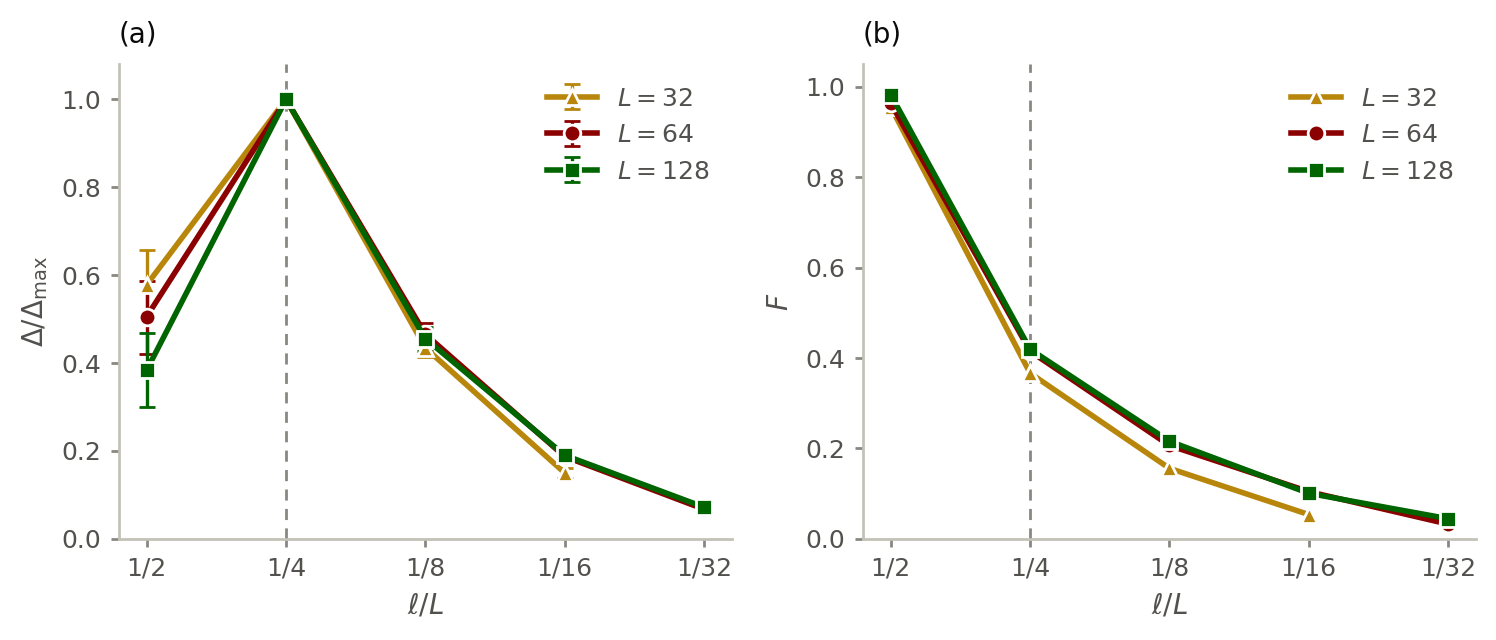

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.6, 3.3), dpi=200, facecolor=BG)
for L in SIZES:
    points = excess["test_pool"][L]["points"]
    shape = np.array([p["shape"] for p in points.values()])
    interval = np.array([p["ci_shape"] for p in points.values()])
    a1.errorbar([float(scale) for scale in points], shape, yerr=[shape - interval[:, 0], interval[:, 1] - shape], color=COLORS[L],
                marker=MARKERS[L], markersize=6, linewidth=2.0, capsize=3, elinewidth=1.2, markeredgecolor=BG, markeredgewidth=1.0,
                label=f"$L={L}$", zorder=3)

    points = scan["test_pool"][L]["points"]
    a2.plot([float(scale) for scale in points], [p["lost_fraction"] for p in points.values()], color=COLORS[L], marker=MARKERS[L],
            markersize=6, linewidth=2.0, markeredgecolor=BG, markeredgewidth=1.0, label=f"$L={L}$", zorder=3)

a1.set_ylim(0, 1.08)
a1.set_xlabel(r"$\ell/L$", fontsize=10, color=LABEL)
a1.set_ylabel(r"$\Delta/\Delta_{\max}$", fontsize=10, color=LABEL)
a1.set_title("(a)", fontsize=10, color=TEXT, loc="left", pad=8)

a2.set_ylim(0, 1.05)
a2.set_xlabel(r"$\ell/L$", fontsize=10, color=LABEL)
a2.set_ylabel("$F$", fontsize=10, color=LABEL)
a2.set_title("(b)", fontsize=10, color=TEXT, loc="left", pad=8)

scales = [float(scale) for scale in excess["test_pool"][128]["points"]]
for ax in (a1, a2):
    ax.set_xscale("log", base=2)
    ax.set_xticks(scales, [f"1/{round(1 / scale)}" for scale in scales])
    ax.invert_xaxis()
    ax.yaxis.set_major_formatter("{x:.1f}")
    ax.axvline(0.25, color=GRAY, linewidth=1.0, linestyle=(0, (4, 3)), zorder=1)
    ax.legend(frameon=False, fontsize=9, labelcolor=LABEL)
    ax.set_facecolor(BG)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["bottom", "left"]].set(color=AXIS, linewidth=1.0)
    ax.tick_params(color=GRAY, labelcolor=LABEL, labelsize=9, length=3, width=1.0)

fig.tight_layout()
fig.savefig("../data_repository/figures/fig_scale.png", bbox_inches="tight")
fig.savefig("../data_repository/figures/fig_scale.pdf", bbox_inches="tight")
plt.close(fig)
display(Image("../data_repository/figures/fig_scale.png"))